Author:  
Manuel Eugenio Morocho Cayamcela, PhD

Tarea realizada por: Alexander Omar Fernández Pérez - 20/10/2026

## Exploratory Data Analysis of the Titanic Dataset

The Titanic was a famous ocean liner that tragically sank on its maiden voyage in 1912. Considered at the time the largest and most luxurious ship in the world, it was a symbol of the opulence and technological progress of the era.

On April 10, 1912, the Titanic departed from Southampton, England, bound for New York. However, on the night of April 14–15, the ship struck an iceberg in the North Atlantic and sank within hours. The disaster killed more than 1,500 people, making it one of the deadliest maritime tragedies in history.

### Introduction

This activity introduces basic exploratory data analysis using pandas and data visualization. We will inspect the dataset's structure, review descriptive statistics, check for missing values, and use plots to assess the hypotheses below.

The dataset is hosted in this GitHub repository, so you do not need to download or share it separately.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

url = "https://raw.githubusercontent.com/eugeniomorocho/ArtificialIntelligence/main/Datasets/titanic.csv"
df = pd.read_csv(url)
df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


Each row represents one passenger, and each column records a passenger attribute.

The dataset contains these columns:

1. `PassengerId`: Unique passenger identifier.
2. `Survived`: Survival status (0 = no, 1 = yes).
3. `Pclass`: Ticket class (1 = first, 2 = second, 3 = third).
4. `Name`: Passenger's name.
5. `Sex`: Passenger's sex.
6. `Age`: Passenger's age.
7. `SibSp`: Number of siblings or spouses aboard.
8. `Parch`: Number of parents or children aboard.
9. `Ticket`: Ticket number.
10. `Fare`: Ticket fare.
11. `Cabin`: Cabin number.
12. `Embarked`: Port of embarkation (C = Cherbourg, Q = Queenstown, S = Southampton).

### Dataset Inspection

In the code cell below, display the dataset dimensions, data types, missing-value counts, and descriptive statistics. Keep the outputs visible. Then use the Markdown cell to identify which columns have missing values and describe one observation from the statistics.

In [2]:
# Inspect the dataset: dimensions, data types, missing values, and descriptive statistics.
# 1. Dimensiones (filas, columnas)
print("Dimensiones:", df.shape)

Dimensiones: (891, 12)


In [3]:
# 2.Tipos de datos
df.dtypes

PassengerId      int64
Survived         int64
Pclass           int64
Name               str
Sex                str
Age            float64
SibSp            int64
Parch            int64
Ticket             str
Fare           float64
Cabin              str
Embarked           str
dtype: object

In [4]:
# 3. Missing values
df.isnull().sum()

PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64

In [5]:
# 4. Estadísticas descriptivas
df.describe()

,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


**Inspection notes:** Summarize what you found in the inspection and whether any preprocessing is needed for the hypotheses below.
- El dataset tiene 891 filas (pasajeros) y 12 columnas.
- Columnas con valores faltantes:
  - Age: 177 faltantes.
  - Cabin: 687 faltantes, casi toda la columna está vacía.
  - Embarked: 2 faltantes.
- Observación de las estadísticas: la media de Survived es 0.38, es decir, solo sobrevivió cerca del 38 % de los pasajeros. También se ve que Fare es muy desigual: la mediana es 14.45 pero el máximo llega a 512.33.
- No hace falta procesar para estas hipótesis. Solo usamos Survived, Sex y Pclass, y esas columnas no tienen valores faltantes.

### Hypothesis Testing

#### Hypothesis 1: Women were more likely to survive

Calculate the survival rate for each sex and create a clearly labeled chart to compare them.

Sex
female    74.2
male      18.9
Name: Survived, dtype: float64


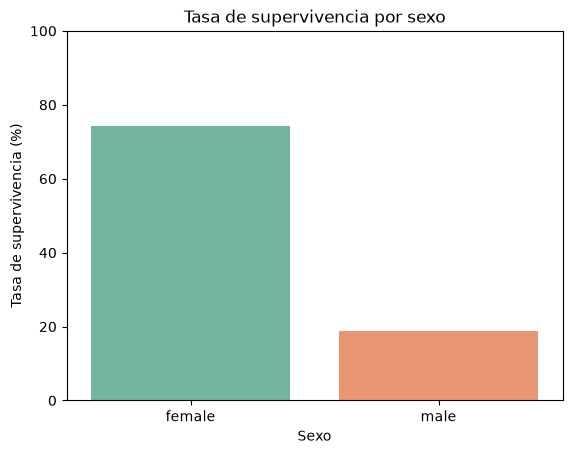

In [6]:
# Calculate survival rates by sex and visualize the comparison.

# Tasa de supervivencia = promedio de Survived por grupo
tasa_sexo = df.groupby("Sex")["Survived"].mean()
print((tasa_sexo * 100).round(1))

# Gráfico de barras
sns.barplot(x=tasa_sexo.index, y=tasa_sexo.values * 100, hue=tasa_sexo.index, palette="Set2", legend=False)
plt.title("Tasa de supervivencia por sexo")
plt.xlabel("Sexo")
plt.ylabel("Tasa de supervivencia (%)")
plt.ylim(0, 100)
plt.show()

**Interpretation:** Which sex had the higher survival rate? Support your conclusion with the rates shown in your output.
- Las mujeres tuvieron una tasa de supervivencia mucho más alta: 74.2 %, frente a solo 18.9 % de los hombres. Es decir, una mujer tenía casi 4 veces más probabilidad de sobrevivir. La hipótesis 1 se cumple, lo que coincide con la regla de "mujeres y niños primero" en los botes salvavidas.

#### Hypothesis 2: First-class passengers were more likely to survive

Calculate the survival rate for each passenger class and create a clearly labeled chart to compare them.

Pclass
1    63.0
2    47.3
3    24.2
Name: Survived, dtype: float64


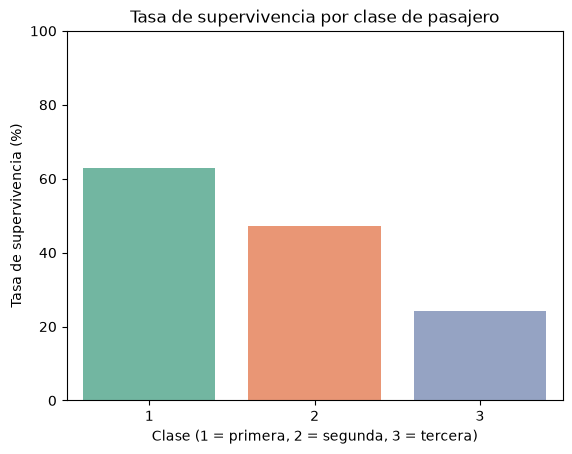

In [7]:
# Calculate survival rates by passenger class and visualize the comparison.

tasa_clase = df.groupby("Pclass")["Survived"].mean()
print((tasa_clase * 100).round(1))

# Gráfico de barras
sns.barplot(x=tasa_clase.index, y=tasa_clase.values * 100, hue=tasa_clase.index, palette="Set2", legend=False)
plt.title("Tasa de supervivencia por clase de pasajero")
plt.xlabel("Clase (1 = primera, 2 = segunda, 3 = tercera)")
plt.ylabel("Tasa de supervivencia (%)")
plt.ylim(0, 100)
plt.show()

**Interpretation:** Which passenger class had the highest survival rate? Support your conclusion with the rates shown in your output.
- La primera clase tuvo la tasa de supervivencia más alta: 63.0 %, seguida de segunda clase con 47.3 % y tercera clase con solo 24.2 %. A mejor clase, mayor supervivencia. La hipótesis 2 se cumple; probablemente porque los camarotes de primera estaban más cerca de la cubierta y los botes salvavidas.

### Assessment Rubric (10 points)

<table style="border-collapse: collapse; border-top: 1px solid; border-bottom: 1px solid;">
  <tr style="border-bottom: 1px solid;"><th style="border-left: none; border-right: none;" align="left">Criterion</th><th style="border-left: none; border-right: none;" align="right">Points</th></tr>
  <tr><td style="border-left: none; border-right: none;">Data inspection: required outputs and notes</td><td style="border-left: none; border-right: none;" align="right">2</td></tr>
  <tr><td style="border-left: none; border-right: none;">Hypothesis 1: survival rates by sex with a labeled chart (3); interpretation (1)</td><td style="border-left: none; border-right: none;" align="right">4</td></tr>
  <tr><td style="border-left: none; border-right: none;">Hypothesis 2: survival rates by class with a labeled chart (3); interpretation (1)</td><td style="border-left: none; border-right: none;" align="right">4</td></tr>
  <tr><td style="border-left: none; border-right: none;"><strong>Total</strong></td><td style="border-left: none; border-right: none;" align="right"><strong>10</strong></td></tr>
</table>